In [1]:
#install all the packages needed for the project
!pip3 install langgraph openai chromadb

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


initialize the LLM client 

In [9]:
import os
from dotenv import load_dotenv  # <--- FIX 1: Import the dotenv loader
from openai import OpenAI

# FIX 2: Explicitly load the hidden .env file into Python memory
load_dotenv()

GROQ_API_KEY = os.getenv('GROQ_API_KEY')

client = OpenAI(api_key=GROQ_API_KEY,
    base_url="https://api.groq.com/openai/v1"
)

def call_llm(prompt, system="You are a helpful assistant."):
    """Simple helper to call the LLM."""
    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {"role": "system", "content": system},
            {"role": "user", "content": prompt}
        ],
        temperature=0.2
    )
    return response.choices[0].message.content


print("Setup Complete")

Setup Complete


In [10]:
call_llm("what is the capital of france?")

'The capital of France is **Paris**.'

intialised the state and created the nodes (nodes are nothing but the python code) , here created 2 nodes greet and make uppercase
[START] → [GREET] → [UPPERCASE] → [END]

In [11]:
state = {}
from typing import TypedDict

class SimpleState(TypedDict):
    name: str
    greeting: str
    final_output: str
def greet(state):
    """Node 1: Create a greeting from the name."""
    name = state["name"]
    greeting = f"Hello, {name}! Welcome to LangGraph Turotial."
    print(f"  [GREET] Created greeting for {name}")
    return {"greeting": greeting}


def make_uppercase(state):
    """Node 2: Convert greeting to uppercase."""
    result = state["greeting"].upper()
    print(f"  [UPPERCASE] Converted to uppercase")
    return {"final_output": result}

In [12]:
from langgraph.graph import StateGraph, START, END

/Users/siddharth/Library/Python/3.9/lib/python/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


created a graph function and initialise the stategraph and add the nodes and also the edge(connection between the nodes )

In [13]:
graph = StateGraph(SimpleState)

# Add Nodes
graph.add_node("greet", greet)
graph.add_node("uppercase", make_uppercase)

# adding edges
graph.add_edge(START, "greet")
graph.add_edge("greet", "uppercase")
graph.add_edge("uppercase", END)

app = graph.compile()

print("Graph is built")

Graph is built


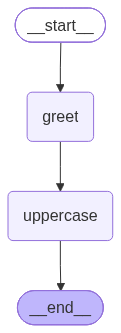

In [14]:
#incase if we want to understand the graph flow
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

execute the flow chart

In [15]:
result = app.invoke({"name": "Aishu"})
print(result)

  [GREET] Created greeting for Aishu
  [UPPERCASE] Converted to uppercase
{'name': 'Aishu', 'greeting': 'Hello, Aishu! Welcome to LangGraph Turotial.', 'final_output': 'HELLO, AISHU! WELCOME TO LANGGRAPH TUROTIAL.'}


In [16]:
print(f"\nFinal result:")
print(f"  Name: {result['name']}")
print(f"  Greeting: {result['greeting']}")
print(f"  Final output: {result['final_output']}")


Final result:
  Name: Aishu
  Greeting: Hello, Aishu! Welcome to LangGraph Turotial.
  Final output: HELLO, AISHU! WELCOME TO LANGGRAPH TUROTIAL.


till now we have seen the flow (just a small flow without using the llm in the nodes )

USING LLM AS NODES

In [17]:
# State for our LLM graph
class LLMState(TypedDict):
    question: str
    topic: str
    answer: str

# Node 1: Analyze the question
def analyze(state):
    """Identify the topic of the question."""
    question = state["question"]
    topic = call_llm(
        f"What is the main topic of this question? Reply with ONE word only: {question}",
        system="You classify questions into topics. Reply with exactly one word."
    )
    print(f"  [ANALYZE] Topic: {topic}")
    return {"topic": topic.strip()}

# Node 2: Generate answer
def respond(state):
    """Answer the question."""
    answer = call_llm(
        f"Topic: {state['topic']}\nQuestion: {state['question']}\nGive a brief answer.",
        system="You are a helpful assistant. Be concise (2-3 sentences max)."
    )
    print(f"  [RESPOND] Answer generated")
    return {"answer": answer}

# Build graph
llm_graph = StateGraph(LLMState)
llm_graph.add_node("analyze", analyze)
llm_graph.add_node("respond", respond)
llm_graph.add_edge(START, "analyze")
llm_graph.add_edge("analyze", "respond")
llm_graph.add_edge("respond", END)

llm_app = llm_graph.compile()
print("✅ LLM Graph ready!")

✅ LLM Graph ready!


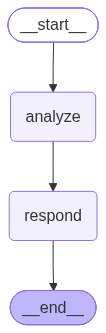

In [18]:
from IPython.display import Image, display

display(Image(llm_app.get_graph().draw_mermaid_png()))

In [19]:
# Test it
result = llm_app.invoke({"question": "What is the capital of France?"})
print(f"\nQuestion: {result['question']}")
print(f"Topic: {result['topic']}")
print(f"Answer: {result['answer']}")

  [ANALYZE] Topic: Geography
  [RESPOND] Answer generated

Question: What is the capital of France?
Topic: Geography
Answer: Paris is the capital of France. It is the country's largest city and a major cultural, political, and economic hub.


In [20]:
# Another question
result = llm_app.invoke({"question": "what is bias variance tradeoff?"})
print(f"\nQuestion: {result['question']}")
print(f"Topic: {result['topic']}")
print(f"Answer: {result['answer']}")

  [ANALYZE] Topic: MachineLearning
  [RESPOND] Answer generated

Question: what is bias variance tradeoff?
Topic: MachineLearning
Answer: The bias‑variance trade‑off describes how a model’s error splits into **bias** (error from overly simple assumptions that cause under‑fitting) and **variance** (error from sensitivity to random fluctuations in the training data that cause over‑fitting). Reducing bias usually increases variance and vice‑versa, so the goal is to find a model complexity that balances the two for the lowest total prediction error.


Conditional Edges - Branching Logic (the previous graph are in a straight flow like (question,analyze,respond,end ))
But here in conditional edges according to the intent (classify intent) and based on the intent decides which conditional edge to follow a node

This is where LangGraph shines. Instead of "always go to the next node," we can say:

"If the intent is billing, go to billing handler. If HR, go to HR handler."

                    ┌── billing → [BILLING] ──┐
[CLASSIFY] ─────── ├── hr      → [HR]      ──├──→ [RESPOND]
                    └── general → [GENERAL] ──┘

In [21]:
# State with intent
class RouterState(TypedDict):
    question: str
    intent: str
    context: str
    answer: str


# Node 1: Classify intent
def classify_intent(state):
    """Classify the user's question into billing/hr/general."""
    question = state["question"]
    intent = call_llm(
        f"Classify this question into exactly one category: billing, hr, or general.\n\nQuestion: {question}\n\nReply with ONLY the category word (billing, hr, or general):",
        system="You classify questions. Reply with exactly one word: billing, hr, or general."
    )
    intent = intent.strip().lower()
    # Ensure valid intent
    if intent not in ["billing", "hr", "general"]:
        intent = "general"
    print(f"  [CLASSIFY] Intent: {intent}")
    return {"intent": intent}
# Node 2a: Handle billing questions
def handle_billing(state):
    """Answer billing-related questions."""
    answer = call_llm(
        state["question"],
        system="You are a billing support agent. Answer questions about subscriptions, pricing, payments, and refunds. Be helpful and concise."
    )
    print(f"  [BILLING] Answered")
    return {"answer": answer, "context": "billing_docs"}
# Node 2b: Handle HR questions
def handle_hr(state):
    """Answer HR-related questions."""
    answer = call_llm(
        state["question"],
        system="You are an HR assistant. Answer questions about leave policy, WFH, probation, and company policies. Be helpful and concise."
    )
    print(f"  [HR] Answered")
    return {"answer": answer, "context": "hr_docs"}
# Node 2c: Handle general questions
def handle_general(state):
    """Answer general questions."""
    answer = call_llm(
        state["question"],
        system="You are a helpful assistant. Answer the question concisely."
    )
    print(f"  [GENERAL] Answered")
    return {"answer": answer, "context": "general_knowledge"}

In [22]:
# The ROUTING function (decides which node to go to)
def route_by_intent(state):
    """Decide which handler to use based on intent."""
    intent = state["intent"]
    if intent == "billing":
        return "handle_billing"
    elif intent == "hr":
        return "handle_hr"
    else:
        return "handle_general"

In [23]:
# Build the graph with conditional edges
router_graph = StateGraph(RouterState)

# Add nodes
router_graph.add_node("classify", classify_intent)
router_graph.add_node("handle_billing", handle_billing)
router_graph.add_node("handle_hr", handle_hr)
router_graph.add_node("handle_general", handle_general)

# Add edges
router_graph.add_edge(START, "classify")

# Use this (with explicit mapping):
router_graph.add_conditional_edges(
    "classify",
    route_by_intent,
    {
        "handle_billing": "handle_billing",
        "handle_hr": "handle_hr",
        "handle_general": "handle_general",
    }
)

# All handlers lead to END
router_graph.add_edge("handle_billing", END)
router_graph.add_edge("handle_hr", END)
router_graph.add_edge("handle_general", END)

router_app = router_graph.compile()
print("✅ Router graph ready!")
print("   Flow: classify → (billing | hr | general) → END")


✅ Router graph ready!
   Flow: classify → (billing | hr | general) → END


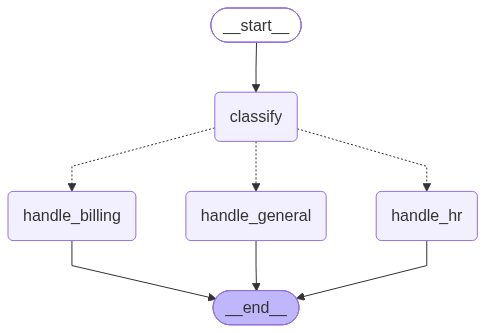

In [24]:
from IPython.display import Image, display

display(Image(router_app.get_graph().draw_mermaid_png()))

In [25]:
# Test: Billing question
print("═" * 60)
result = router_app.invoke({"question": "How do I cancel my subscription?"})
print(f"\nIntent: {result['intent']}")
print(f"Answer: {result['answer']}")

════════════════════════════════════════════════════════════
  [CLASSIFY] Intent: billing
  [BILLING] Answered

Intent: billing
Answer: Sure! Here’s how to cancel your subscription:

1. **Log in to your account**  
   Go to the website or app where you signed up and sign in.

2. **Open Account/Settings**  
   - On the web: Click your profile picture or name in the top‑right corner → **Account Settings**.  
   - In the app: Tap the menu (☰) → **Settings**.

3. **Find the Subscription/Billing section**  
   Look for a tab labeled **Subscription**, **Billing**, **Plan**, or **Payments**.

4. **Select “Cancel Subscription”**  
   - Click **Cancel**, **Cancel Plan**, or **End Membership**.  
   - You may be asked to confirm the cancellation—confirm it.

5. **Complete the process**  
   You should receive a confirmation email (or in‑app notification) that your subscription is set to cancel at the end of the current billing cycle.

**A few quick notes**

- **When does it take effect?** Your a

In [26]:
# Test: General question
print("═" * 60)
result = router_app.invoke({"question": "What is machine learning?"})
print(f"\nIntent: {result['intent']}")
print(f"Answer: {result['answer']}")

════════════════════════════════════════════════════════════
  [CLASSIFY] Intent: general
  [GENERAL] Answered

Intent: general
Answer: Machine learning is a branch of artificial intelligence that enables computers to learn patterns and make decisions from data without being explicitly programmed. By training algorithms on examples, the system improves its performance on tasks such as classification, prediction, or clustering as it encounters more data.


ADD retry logic in the llm call
the llm used API call to get the information ,but what if due to any issue you have not got the answer , so you add the retry logic in tha llm call 

In [27]:
import time

def generate_with_retry(state):
    """Generate answer with retry logic inside the node."""
    question = state["question"]

    for attempt in range(3):
        try:
            answer = call_llm(question)
            print(f"  [GENERATE] Success on attempt {attempt + 1}")
            return {"answer": answer}
        except Exception as e:
            print(f"  [GENERATE] Attempt {attempt + 1} failed: {e}")
            if attempt < 2:
                wait = 2 ** attempt
                print(f"  [GENERATE] Waiting {wait}s before retry...")
                time.sleep(wait)

    # All retries failed
    return {"answer": "Sorry, I couldn't generate an answer. Please try again later."}

print("✅ Retry node defined")
print("   Pattern: try → fail → wait 1s → try → fail → wait 2s → try → give up")

✅ Retry node defined
   Pattern: try → fail → wait 1s → try → fail → wait 2s → try → give up


till now we have call the llm via api and got the generalised answer from the llm 
now we will get the output from our text,docs,pdf ect using RAG(we use chromadb to do the embeddings )=> indexing 

Mini-Build — Customer Support Router with RAG
Let's combine everything: classification + RAG retrieval + conditional routing.

This is a real-world pattern — a customer support bot that routes questions to the right knowledge base.

[CLASSIFY] → billing? → [SEARCH billing docs] → [GENERATE answer]
           → hr?      → [SEARCH hr docs]      → [GENERATE answer]
           → general? → [LLM answers directly]

In [28]:
import chromadb

# Setup ChromaDB with our documents
chroma_client = chromadb.Client()

# Create two collections (simulating different knowledge bases)
try:
    chroma_client.delete_collection("billing_docs")
    chroma_client.delete_collection("hr_docs")
except:
    pass

billing_collection = chroma_client.create_collection("billing_docs")
hr_collection = chroma_client.create_collection("hr_docs")

# Add some billing knowledge
billing_docs = [
    "Monthly subscriptions can be cancelled anytime from Settings > Billing > Cancel. You will retain access until the end of your current billing period.",
    "Refunds for annual plans are available within 30 days of purchase. After 30 days, annual subscriptions are non-refundable.",
    "Payment methods accepted: credit card (Visa, Mastercard), debit card, UPI, and net banking. International cards are supported.",
    "If a payment fails, the system retries 3 times over 7 days. After that, your account enters a 14-day grace period.",
    "Upgrade from Starter to Business plan takes effect immediately with prorated charges for the remaining billing period.",
]

# Add some HR knowledge
hr_docs = [
    "All full-time employees get 24 days of paid annual leave per year, accruing at 2 days per month.",
    "Sick leave is 12 days per year. More than 3 consecutive days requires a medical certificate.",
    "Work from home is available up to 2 days per week (Wednesday and Friday preferred) after completing the 6-month probation period.",
    "Probation period is 6 months. During probation, either party can terminate with 15 days notice.",
    "Annual performance reviews happen in March. Ratings: Exceptional, Exceeds, Meets, Needs Improvement, Unsatisfactory.",
]

billing_collection.add(documents=billing_docs, ids=[f"b{i}" for i in range(len(billing_docs))])
hr_collection.add(documents=hr_docs, ids=[f"h{i}" for i in range(len(hr_docs))])

print(f"✅ Billing KB: {len(billing_docs)} docs")
print(f"✅ HR KB: {len(hr_docs)} docs")

✅ Billing KB: 5 docs
✅ HR KB: 5 docs


In [31]:
# ──────────────────────────────────────
# The Complete Customer Support Graph
# ──────────────────────────────────────

class SupportState(TypedDict):
    question: str
    intent: str
    context: str
    answer: str
    source: str

def classify(state):
    """Classify the question."""
    intent = call_llm(
        f"Classify this customer question into: billing, hr, or general.\nQuestion: {state['question']}\nReply with ONE word only:",
        system="Reply with exactly one word: billing, hr, or general."
    ).strip().lower()
    if intent not in ["billing", "hr", "general"]:
        intent = "general"
    print(f"  [CLASSIFY] → {intent}")
    return {"intent": intent}

def search_billing(state):
    """Search billing documents."""
    results = billing_collection.query(query_texts=[state["question"]], n_results=2)
    context = "\n".join(results["documents"][0])
    print(f"  [BILLING RAG] Retrieved {len(results['documents'][0])} chunks")
    return {"context": context, "source": "billing_docs"}

def search_hr(state):
    """Search HR documents."""
    results = hr_collection.query(query_texts=[state["question"]], n_results=2)
    context = "\n".join(results["documents"][0])
    print(f"  [HR RAG] Retrieved {len(results['documents'][0])} chunks")
    return {"context": context, "source": "hr_docs"}

def answer_general(state):
    """Answer general questions directly."""
    answer = call_llm(state["question"])
    print(f"  [GENERAL] Answered directly")
    return {"answer": answer, "source": "general_knowledge", "context": ""}

def generate_answer(state):
    """Generate answer from retrieved context."""
    answer = call_llm(
        f"Context:\n{state['context']}\n\nQuestion: {state['question']}\n\nAnswer using only the context above. Be concise.",
        system="Answer customer questions using only the provided context. If context doesn't have the answer, say so."
    )
    print(f"  [GENERATE] Answer ready")
    return {"answer": answer}

def route(state):
    """Route based on intent."""
    if state["intent"] == "billing":
        return "search_billing"
    elif state["intent"] == "hr":
        return "search_hr"
    else:
        return "answer_general"

# Build the graph
support_graph = StateGraph(SupportState)

support_graph.add_node("classify", classify)
support_graph.add_node("search_billing", search_billing)
support_graph.add_node("search_hr", search_hr)
support_graph.add_node("answer_general", answer_general)
support_graph.add_node("generate", generate_answer)

# Edges
support_graph.add_edge(START, "classify")

support_graph.add_conditional_edges(
    "classify",
    route,
    {
        "billing": "search_billing",
        "hr":      "search_hr",
        "general": "answer_general",
    }
)

support_graph.add_edge("search_billing", "generate")
support_graph.add_edge("search_hr",      "generate")
support_graph.add_edge("answer_general", END)
support_graph.add_edge("generate",       END)

support_app = support_graph.compile()
print("✅ Customer Support Router ready!")

✅ Customer Support Router ready!


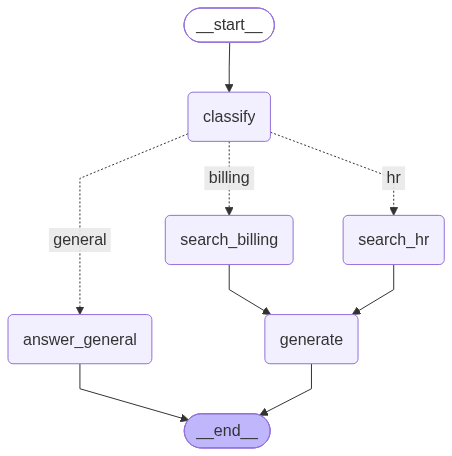

In [32]:
from IPython.display import Image, display

display(Image(support_app.get_graph().draw_mermaid_png()))

In [33]:
# Test: Billing question
print("═" * 60)
result = router_app.invoke({"question": "How do I cancel my subscription?"})
print(f"\nIntent: {result['intent']}")
print(f"Answer: {result['answer']}")

════════════════════════════════════════════════════════════
  [CLASSIFY] Intent: billing
  [BILLING] Answered

Intent: billing
Answer: Sure! Here’s how to cancel your subscription:

1. **Log in** to your account on our website or app.  
2. Go to **Account → Billing → Subscriptions** (or “Manage Subscription”).  
3. Find the active plan you want to cancel and click **Cancel Subscription**.  
4. Follow the prompts to confirm the cancellation. You’ll receive an email confirmation.

**What happens next?**  
- Your subscription will remain active until the end of the current billing period.  
- No further charges will be applied.  
- If you change your mind, you can reactivate the plan anytime before the period ends.

**Need help?**  
If you can’t locate the cancellation option or run into any issues, just reply here or contact our support team at support@yourcompany.com (or via the in‑app chat) and we’ll take care of it for you.


In [34]:
# Test: HR question
print("═" * 60)
result = router_app.invoke({"question": "How many sick leave days do I get?"})
print(f"\nIntent: {result['intent']}")
print(f"Answer: {result['answer']}")

════════════════════════════════════════════════════════════
  [CLASSIFY] Intent: hr
  [HR] Answered

Intent: hr
Answer: The number of sick‑leave days you’re entitled to depends on your location, length of service, and the specific policy outlined in our employee handbook.  

**Typical framework (for most U.S. locations):**  

| Tenure | Paid Sick‑Leave Days per Year |
|--------|------------------------------|
| < 6 months (probation) | 5 days |
| 6 months – 2 years | 7 days |
| > 2 years | 10 days (accrues monthly) |

**Key points**

1. **Accrual** – Sick leave usually accrues each pay period (e.g., 0.42 day per month) and rolls over up to a maximum balance (often 1.5 × annual entitlement).  
2. **Usage** – You can use sick leave for personal illness, medical appointments, or caring for an immediate family member.  
3. **Documentation** – For absences of 3 consecutive days or more, a doctor’s note is typically required.  
4. **Where to verify** – Check the “Leave & Absence” section of

In [35]:
# Test: General question
print("═" * 60)
result = router_app.invoke({"question": "What is machine learning?"})
print(f"\nIntent: {result['intent']}")
print(f"Answer: {result['answer']}")

════════════════════════════════════════════════════════════
  [CLASSIFY] Intent: general
  [GENERAL] Answered

Intent: general
Answer: Machine learning is a branch of artificial intelligence that enables computers to learn patterns and make decisions from data without being explicitly programmed. By training algorithms on examples, the system improves its performance on tasks such as classification, prediction, or clustering as it encounters more data.
